In [1]:
import pyodbc
import pandas as pd

# Connexion
conn = pyodbc.connect('Driver={SQL Server};'
                      'Server=localhost;'
                      'Database=DW_SupplyChain;'
                      'Trusted_Connection=yes;')

query = '''
SELECT
    Production_Start_Time,
    quantityused
FROM fact_production
'''

df = pd.read_sql(query, conn)
df.head()



C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
C:\Users\ayadi\AppData\Local\Temp\ipykernel_30348\4263625606.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,Production_Start_Time,quantityused
0,2022032723,9
1,2022040823,9
2,2022050523,9
3,2022052123,9
4,2022070123,9


In [2]:
# Conversion de Production_Start_Time en datetime
df['Production_Start_Time'] = pd.to_datetime(df['Production_Start_Time'].astype(str), format='%Y%m%d%H')

# On renomme la colonne pour plus de clarté
df.rename(columns={'Production_Start_Time': 'Starttimeprod'}, inplace=True)

# Affichage des premières lignes
df.head()


,Starttimeprod,quantityused
0,2022-03-27 23:00:00,9
1,2022-04-08 23:00:00,9
2,2022-05-05 23:00:00,9
3,2022-05-21 23:00:00,9
4,2022-07-01 23:00:00,9


In [3]:
# Vérifier les valeurs manquantes
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())

# Statistiques descriptives rapides
print("\nStatistiques descriptives :")
print(df['quantityused'].describe())


Valeurs manquantes par colonne :
Starttimeprod    0
quantityused     0
dtype: int64

Statistiques descriptives :
count     33043
unique       10
top           5
freq       3918
Name: quantityused, dtype: object


In [4]:
# Conversion de quantityused en numérique (au cas où ce n'est pas le cas)
df['quantityused'] = pd.to_numeric(df['quantityused'], errors='coerce')

# Vérification après conversion
print(df['quantityused'].describe())


count    33043.000000
mean         5.410435
std          2.911730
min          1.000000
25%          3.000000
50%          5.000000
75%          8.000000
max         10.000000
Name: quantityused, dtype: float64


In [5]:
# On place Starttimeprod comme index temporel
df.set_index('Starttimeprod', inplace=True)

# Agrégation par mois (somme totale des productions par mois)
monthly_data = df.resample('M').sum()

# Affichage des premières lignes
monthly_data.head()


C:\Users\ayadi\AppData\Local\Temp\ipykernel_30348\748593862.py:5: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_data = df.resample('M').sum()


,quantityused
Starttimeprod,
2022-01-31,5021
2022-02-28,4645
2022-03-31,5169
2022-04-30,4729
2022-05-31,5066


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


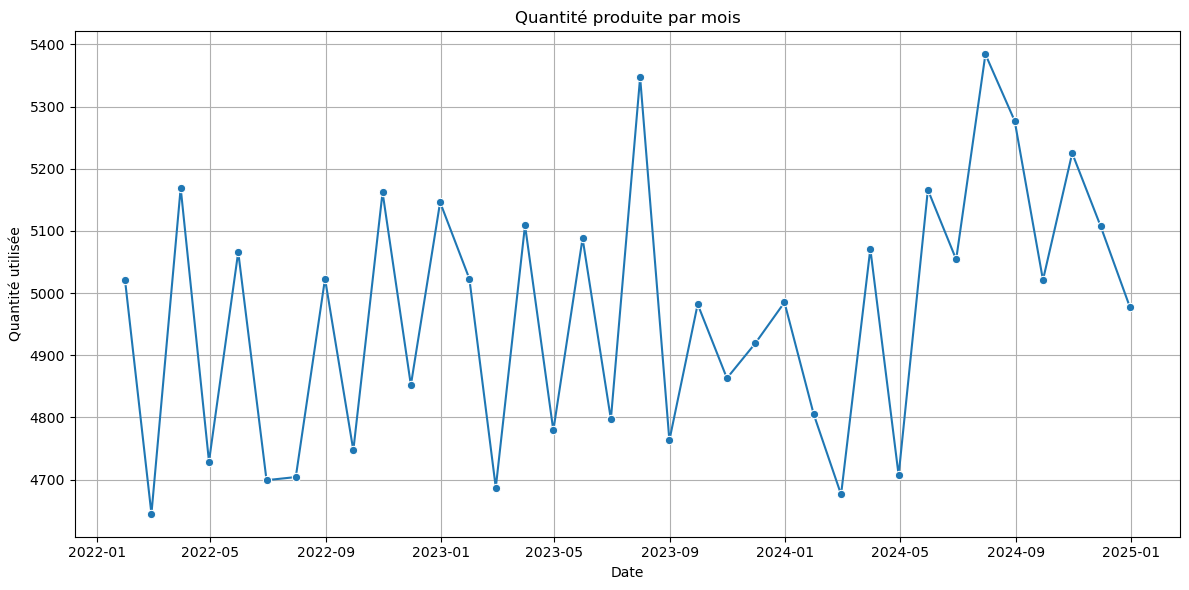

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Taille et style
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_data, x=monthly_data.index, y='quantityused', marker='o')
plt.title("Quantité produite par mois")
plt.xlabel("Date")
plt.ylabel("Quantité utilisée")
plt.grid(True)
plt.tight_layout()
plt.show()


C:\Users\ayadi\AppData\Local\Temp\ipykernel_30348\2405056417.py:9: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


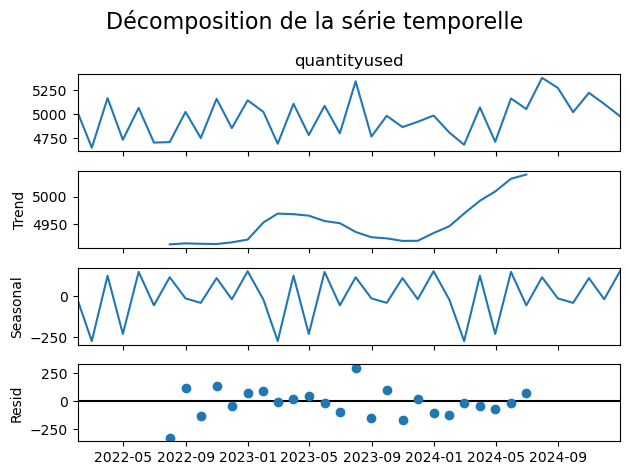

In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Décomposition avec spécification manuelle de la périodicité mensuelle (12 mois)
decomposition = seasonal_decompose(monthly_data['quantityused'], model='additive', period=12)

# Affichage des composantes
decomposition.plot()
plt.suptitle("Décomposition de la série temporelle", fontsize=16)
plt.tight_layout()
plt.show()


In [8]:
from statsmodels.tsa.stattools import adfuller

# Test ADF sur la série originale
result = adfuller(monthly_data['quantityused'])

print("=== Test de Dickey-Fuller ===")
print(f"Statistique ADF : {result[0]:.4f}")
print(f"P-value : {result[1]:.4f}")
for key, value in result[4].items():
    print(f"Seuil critique {key} : {value:.4f}")


=== Test de Dickey-Fuller ===
Statistique ADF : -2.6561
P-value : 0.0820
Seuil critique 1% : -3.6392
Seuil critique 5% : -2.9512
Seuil critique 10% : -2.6144


In [9]:
# Différenciation de la série
diff_data = monthly_data['quantityused'].diff().dropna()

# Test ADF sur la série différenciée
result_diff = adfuller(diff_data)

print("=== Test ADF après différenciation ===")
print(f"Statistique ADF : {result_diff[0]:.4f}")
print(f"P-value : {result_diff[1]:.4f}")
for key, value in result_diff[4].items():
    print(f"Seuil critique {key} : {value:.4f}")


=== Test ADF après différenciation ===
Statistique ADF : -6.9506
P-value : 0.0000
Seuil critique 1% : -3.6461
Seuil critique 5% : -2.9541
Seuil critique 10% : -2.6160


In [10]:
pip install pmdarima


Note: you may need to restart the kernel to use updated packages.


In [11]:
from pmdarima import auto_arima

# auto_arima suppose que l'index est de type datetime et bien ordonné
stepwise_model = auto_arima(
    monthly_data['quantityused'],
    start_p=1, start_q=1,
    max_p=3, max_q=3,
    seasonal=True,
    m=12,               # saisonnalité annuelle (12 mois)
    d=None,             # différenciation automatique
    D=None,             # différenciation saisonnière automatique
    trace=True,
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True
)

# Résumé du modèle
print(stepwise_model.summary())


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will b

Performing stepwise search to minimize aic
 ARIMA(1,0,1)(1,0,1)[12] intercept   : AIC=491.273, Time=0.32 sec
 ARIMA(0,0,0)(0,0,0)[12] intercept   : AIC=488.284, Time=0.01 sec
 ARIMA(1,0,0)(1,0,0)[12] intercept   : AIC=490.570, Time=0.08 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : AIC=489.395, Time=0.08 sec
 ARIMA(0,0,0)(0,0,0)[12]             : AIC=716.970, Time=0.01 sec
 ARIMA(0,0,0)(1,0,0)[12] intercept   : AIC=490.281, Time=0.02 sec


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will b

 ARIMA(0,0,0)(0,0,1)[12] intercept   : AIC=487.893, Time=0.07 sec
 ARIMA(0,0,0)(1,0,1)[12] intercept   : AIC=490.068, Time=0.06 sec
 ARIMA(0,0,0)(0,0,2)[12] intercept   : AIC=489.417, Time=0.08 sec


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(0,0,0)(1,0,2)[12] intercept   : AIC=491.696, Time=0.11 sec
 ARIMA(1,0,0)(0,0,1)[12] intercept   : AIC=488.997, Time=0.09 sec
 ARIMA(1,0,1)(0,0,1)[12] intercept   : AIC=491.493, Time=0.09 sec


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(0,0,0)(0,0,1)[12]             : AIC=inf, Time=0.05 sec

Best model:  ARIMA(0,0,0)(0,0,1)[12] intercept
Total fit time: 1.103 seconds
                                 SARIMAX Results                                  
Dep. Variable:                          y   No. Observations:                   36
Model:             SARIMAX(0, 0, [1], 12)   Log Likelihood                -240.947
Date:                    Sun, 13 Apr 2025   AIC                            487.893
Time:                            14:30:43   BIC                            492.644
Sample:                        01-31-2022   HQIC                           489.551
                             - 12-31-2024                                         
Covariance Type:                      opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   4969.3455     41.051    12

C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


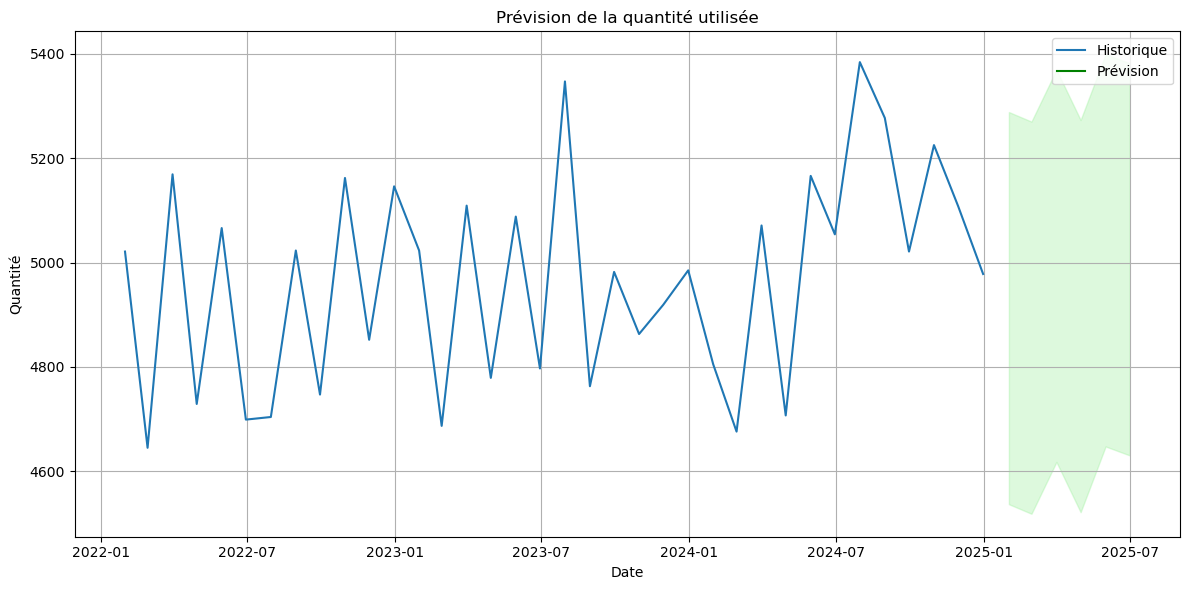

In [12]:
# Prédiction des 6 mois à venir
n_periods = 6
forecast, conf_int = stepwise_model.predict(n_periods=n_periods, return_conf_int=True)

# Index des prévisions
forecast_index = pd.date_range(start=monthly_data.index[-1] + pd.DateOffset(months=1), periods=n_periods, freq='MS')

# Création d’un DataFrame des prévisions
forecast_df = pd.DataFrame({
    'Forecast': forecast,
    'Lower CI': conf_int[:, 0],
    'Upper CI': conf_int[:, 1]
}, index=forecast_index)

# Affichage
plt.figure(figsize=(12, 6))
plt.plot(monthly_data.index, monthly_data['quantityused'], label='Historique')
plt.plot(forecast_df.index, forecast_df['Forecast'], label='Prévision', color='green')
plt.fill_between(forecast_df.index, forecast_df['Lower CI'], forecast_df['Upper CI'], color='lightgreen', alpha=0.3)
plt.title("Prévision de la quantité utilisée")
plt.xlabel("Date")
plt.ylabel("Quantité")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [13]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Préparation de la série
series = monthly_data[['quantityused']].copy()
series.index = pd.to_datetime(series.index)
series = series.sort_index()

# Normalisation entre 0 et 1
scaler = MinMaxScaler()
scaled_series = scaler.fit_transform(series)

# Transformation en séquences pour LSTM
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(window_size, len(data)):
        X.append(data[i - window_size:i])
        y.append(data[i])
    return np.array(X), np.array(y)

window_size = 3  # par exemple, 3 mois glissants
X_lstm, y_lstm = create_sequences(scaled_series, window_size)

# Reshape pour LSTM (échantillons, timesteps, features)
X_lstm = X_lstm.reshape((X_lstm.shape[0], X_lstm.shape[1], 1))
